Support vector regression takes the SVM machinery &mdash; margins, support vectors, kernels &mdash;
and points it at a continuous target. The translation rests on one inversion:

> **Classification:** keep points *outside* the margin.
> **Regression:** keep points *inside* a tube.

Least squares penalises every residual, however small. SVR ignores errors below a
tolerance $\varepsilon$ entirely:

$$L_\varepsilon(y, \hat y) = \max\big(0,\; |y - \hat y| - \varepsilon\big)$$

That flat region has real consequences. Points inside the tube have zero gradient, so
they contribute nothing and are discarded &mdash; giving a **sparse** model built from a few
boundary points, just like the classifier. And because errors below $\varepsilon$ cost
nothing, the fit is insensitive to small noise while remaining only linearly &mdash; not
quadratically &mdash; sensitive to outliers.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)
np.set_printoptions(precision=4, suppress=True, linewidth=140)


def banner(title, ch="="):
    print(ch * 78)
    print(f"  {title}")
    print(ch * 78)


def step(label):
    print()
    print(label)
    print("=" * 78)


def check(manual, from_array, label="MATCH"):
    ok = np.allclose(manual, from_array)
    print(f"      = {manual:+.6f}   |  from array: {from_array:+.6f}   |  {label}: {ok}")
    return ok


def expand(u, v, per_line=4):
    """Write a dot product out term by term."""
    terms = [f"({a:+.4f})*({b:+.4f})" for a, b in zip(u, v)]
    lines, out = [], ""
    for i, t in enumerate(terms):
        out += t + (" + " if i < len(terms) - 1 else "")
        if (i + 1) % per_line == 0:
            lines.append(out); out = ""
    if out:
        lines.append(out)
    return "\n      ".join(lines)


def show_matrix(M, name="M", rows=None, cols=None, fmt="{:+8.3f}", max_cols=14):
    M = np.asarray(M)
    if M.ndim == 1:
        M = M[None, :]
    cut = M.shape[1] > max_cols
    Ms = M[:, :max_cols] if cut else M
    print(f"{name} {np.asarray(M).shape}" +
          (f"   [first {max_cols} of {M.shape[1]} columns]" if cut else "") + " =")
    if cols is not None:
        head = "".join(f"{str(c):>10}" for c in (cols[:max_cols] if cut else cols))
        print(" " * 13 + head)
    for r in range(Ms.shape[0]):
        lab = f"{str(rows[r]):>10} | " if rows is not None else f"{r:>10} | "
        print("   " + lab + "  ".join(fmt.format(v) for v in Ms[r]))


def show_matmul(A, B, C, na="A", nb="B", nc="C", i=0, j=0,
                rows_A=None, note=None, max_cols=14):
    """Print both operands of A @ B = C, then verify one element by hand."""
    A, B, C = np.asarray(A), np.asarray(B), np.asarray(C)
    banner(f"{na} {A.shape}   @   {nb} {B.shape}   =   {nc} {C.shape}")
    print(f"  shape rule: ({A.shape[0]} x {A.shape[1]}) @ ({B.shape[0]} x {B.shape[1]})"
          f" -> ({A.shape[0]} x {B.shape[1]})   inner dim {A.shape[1]} cancels")
    if note:
        print(f"  {note}")
    print("=" * 78)
    print()
    show_matrix(A, na, rows_A, max_cols=max_cols)
    print()
    show_matrix(B, nb, max_cols=max_cols)
    print()
    show_matrix(C, nc, rows_A, max_cols=max_cols)
    print(f"\n  worked element  {nc}[{i},{j}]  =  row {i} of {na}  .  column {j} of {nb}")
    print(f"      row {i} of {na} = {np.round(A[i], 4)}")
    print(f"      col {j} of {nb} = {np.round(B[:, j], 4)}")
    print(f"      {expand(A[i], B[:, j])}")
    check(float(A[i] @ B[:, j]), float(C[i, j]))


def show_elementwise(A, B, C, na, nb, nc, op="+", rows=None):
    A, B, C = np.asarray(A), np.asarray(B), np.asarray(C)
    banner(f"{nc} = {na} {op} {nb}      all three are {A.shape} - element-wise")
    for r in range(A.shape[0]):
        lab = f"{rows[r]:>10}" if rows is not None else f"{r:>10}"
        print(f"\n{lab} |")
        print("   " + f"{na:>14}: " + "  ".join(f"{v:+8.3f}" for v in A[r]))
        print("   " + f"{nb:>14}: " + "  ".join(f"{v:+8.3f}" for v in B[r]))
        print("   " + f"{nc:>14}: " + "  ".join(f"{v:+8.3f}" for v in C[r]))
    print(f"\n  check [0,0]: {A[0,0]:+.6f} {op} {B[0,0]:+.6f} = {C[0,0]:+.6f}   "
          f"MATCH: {np.isclose(A[0,0] + B[0,0] if op == '+' else A[0,0] - B[0,0], C[0,0])}")


print("Display helpers ready: banner, step, check, expand, show_matrix, "
      "show_matmul, show_elementwise.")

Display helpers ready: banner, step, check, expand, show_matrix, show_matmul, show_elementwise.


---
# 1. The Data

The 12 EEG recordings with the continuous target `y_reg` (seizure burden, minutes/hour),
the same one used in the XGBoost walkthrough.

Features are standardised: SVR measures distances in feature space, so unscaled columns
would dominate the kernel exactly as they do for KNN and SVM.

In [2]:
# ----------------------------------------------------------------------------
#  A deliberately tiny EEG-flavoured table: 12 recordings, hand-checkable.
# ----------------------------------------------------------------------------
feature_names = ["line_length", "spike_rate", "age"]
region_names  = ["frontal", "temporal", "occipital"]

X = np.array([
    [12.0,  0.5, 24.0],
    [15.0,  1.2, 31.0],
    [42.0,  6.8, 58.0],
    [38.0,  5.1, 47.0],
    [11.0,  0.3, 19.0],
    [55.0,  8.2, 63.0],
    [40.0,  1.9, 35.0],
    [47.0,  7.4, 52.0],
    [14.0,  0.8, 28.0],
    [51.0,  6.1, 60.0],
    [45.0,  2.4, 41.0],
    [35.0,  4.7, 30.0],
])

# categorical column, used by the CatBoost notebook
region = np.array([0, 1, 1, 2, 0, 1, 2, 1, 0, 2, 0, 1])

# binary target: did a seizure follow?
y_class = np.array([0, 0, 1, 1, 0, 1, 1, 1, 0, 1, 0, 1])

# continuous target: seizure burden in minutes/hour
y_reg = np.array([0.2, 0.5, 6.4, 4.8, 0.1, 9.1, 3.5, 7.2, 0.3, 6.9, 1.6, 4.1])

n_samples, n_features = X.shape
rec_ids = [f"rec{i:02d}" for i in range(n_samples)]

print(f"{n_samples} recordings x {n_features} features\n")
hdr = f"{'id':>6}  {'region':>10}  " + "  ".join(f"{f:>12}" for f in feature_names)
hdr += f"  {'y_class':>8}  {'y_reg':>7}"
print(hdr)
print("-" * len(hdr))
for i in range(n_samples):
    print(f"{rec_ids[i]:>6}  {region_names[region[i]]:>10}  " +
          "  ".join(f"{v:>12.1f}" for v in X[i]) +
          f"  {y_class[i]:>8}  {y_reg[i]:>7.1f}")
print("-" * len(hdr))
print(f"\nclass balance: {int((y_class==0).sum())} negative, {int((y_class==1).sum())} positive")
print(f"y_reg mean = {y_reg.mean():.4f}, std = {y_reg.std():.4f}")

12 recordings x 3 features

    id      region   line_length    spike_rate           age   y_class    y_reg
-------------------------------------------------------------------------------
 rec00     frontal          12.0           0.5          24.0         0      0.2
 rec01    temporal          15.0           1.2          31.0         0      0.5
 rec02    temporal          42.0           6.8          58.0         1      6.4
 rec03   occipital          38.0           5.1          47.0         1      4.8
 rec04     frontal          11.0           0.3          19.0         0      0.1
 rec05    temporal          55.0           8.2          63.0         1      9.1
 rec06   occipital          40.0           1.9          35.0         1      3.5
 rec07    temporal          47.0           7.4          52.0         1      7.2
 rec08     frontal          14.0           0.8          28.0         0      0.3
 rec09   occipital          51.0           6.1          60.0         1      6.9
 rec10     f

In [3]:
from sklearn.svm import SVR

y = y_reg.astype(float)
Xz = (X - X.mean(axis=0)) / X.std(axis=0)

print(f"target y: mean {y.mean():.4f}, std {y.std():.4f}, "
      f"range [{y.min():.1f}, {y.max():.1f}]\n")
print("standardised features:\n")
show_matrix(Xz, "X (standardised)", rows=rec_ids, cols=feature_names)

target y: mean 3.7250, std 3.0518, range [0.1, 9.1]

standardised features:

X (standardised) (12, 3) =
             line_lengthspike_rate       age
        rec00 |   -1.397    -1.176    -1.157
        rec01 |   -1.204    -0.925    -0.671
        rec02 |   +0.530    +1.080    +1.204
        rec03 |   +0.273    +0.472    +0.440
        rec04 |   -1.461    -1.247    -1.505
        rec05 |   +1.365    +1.582    +1.551
        rec06 |   +0.401    -0.674    -0.393
        rec07 |   +0.851    +1.295    +0.787
        rec08 |   -1.268    -1.068    -0.880
        rec09 |   +1.108    +0.830    +1.342
        rec10 |   +0.722    -0.495    +0.023
        rec11 |   +0.080    +0.328    -0.741


---
# 2. The $\varepsilon$-Insensitive Tube

$$\min_{\mathbf{w},b,\xi,\xi^*} \;\; \frac{1}{2}\lVert\mathbf{w}\rVert^2
+ C\sum_i(\xi_i + \xi_i^*)$$

$$\text{s.t.}\quad
\begin{cases}
y_i - (\mathbf{w}^\top\mathbf{x}_i + b) \le \varepsilon + \xi_i \\[2pt]
(\mathbf{w}^\top\mathbf{x}_i + b) - y_i \le \varepsilon + \xi_i^* \\[2pt]
\xi_i, \xi_i^* \ge 0
\end{cases}$$

Two slack variables are needed because a point can miss the tube from above **or** below,
and those are different violations.

Compare the three loss shapes:

| Loss | Formula | Behaviour |
|---|---|---|
| Squared | $(y-\hat y)^2$ | every error counts; outliers dominate |
| Absolute | $\lvert y-\hat y\rvert$ | robust, but every error still counts |
| $\varepsilon$-insensitive | $\max(0, \lvert y-\hat y\rvert - \varepsilon)$ | small errors are **free** |

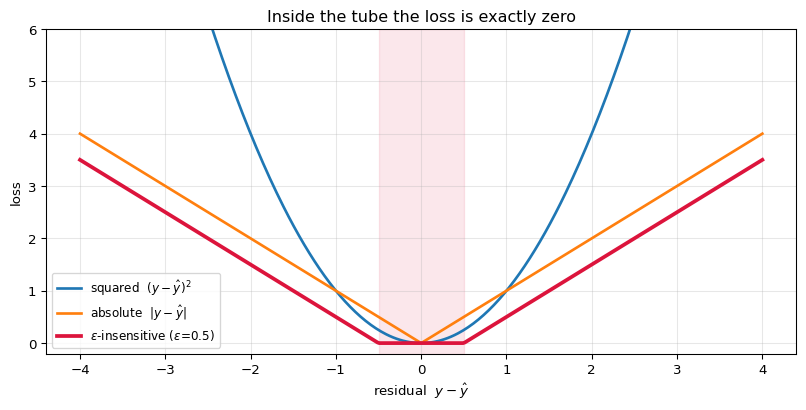

  residual    squared   absolute   eps-insensitive
--------------------------------------------------
       0.0      0.000      0.000             0.000
       0.2      0.040      0.200             0.000
       0.5      0.250      0.500             0.000
       1.0      1.000      1.000             0.500
       2.0      4.000      2.000             1.500
       4.0     16.000      4.000             3.500
--------------------------------------------------

At a residual of 0.2 the squared loss still pushes back; the
eps-insensitive loss is flat, so that point exerts NO force on the fit.
At a residual of 4 the squared loss is 4.6x larger - which is
why least squares is dragged around by outliers and SVR is not.


In [4]:
EPS, CVAL = 0.5, 10.0
err = np.linspace(-4, 4, 400)

fig, ax = plt.subplots(figsize=(8.5, 4.4))
ax.plot(err, err**2, lw=2, label="squared  $(y-\\hat y)^2$")
ax.plot(err, np.abs(err), lw=2, label="absolute  $|y-\\hat y|$")
ax.plot(err, np.maximum(0, np.abs(err)-EPS), lw=2.8, color="crimson",
        label=f"$\\varepsilon$-insensitive ($\\varepsilon$={EPS})")
ax.axvspan(-EPS, EPS, color="crimson", alpha=.10)
ax.set(xlabel="residual  $y - \\hat y$", ylabel="loss", ylim=(-.2, 6),
       title="Inside the tube the loss is exactly zero")
ax.legend(fontsize=9); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

print(f"{'residual':>10}  {'squared':>9}  {'absolute':>9}  {'eps-insensitive':>16}")
print("-" * 50)
for e in (0.0, 0.2, 0.5, 1.0, 2.0, 4.0):
    print(f"{e:>10.1f}  {e**2:>9.3f}  {e:>9.3f}  {max(0, e-EPS):>16.3f}")
print("-" * 50)
print(f"\nAt a residual of 0.2 the squared loss still pushes back; the")
print(f"eps-insensitive loss is flat, so that point exerts NO force on the fit.")
print(f"At a residual of 4 the squared loss is {16/(4-EPS):.1f}x larger - which is")
print(f"why least squares is dragged around by outliers and SVR is not.")

---
# 3. The Tube on Real Data

Fitting a linear SVR to one feature makes the geometry visible: a central line, two
dashed walls at $\pm\varepsilon$, and support vectors circled.

In [5]:
x1 = Xz[:, 1:2]                      # spike_rate, standardised
svr1 = SVR(kernel="linear", C=CVAL, epsilon=EPS).fit(x1, y)
pred1 = svr1.predict(x1)
resid1 = y - pred1

print(f"linear SVR on '{feature_names[1]}' alone   "
      f"(C = {CVAL}, epsilon = {EPS})\n")
print(f"   w = {svr1.coef_[0][0]:+.6f}   b = {float(svr1.intercept_[0]):+.6f}")
print(f"   support vectors: {len(svr1.support_)} of {n_samples}\n")

print(f"{'id':>6}  {'x (z)':>8}  {'y':>7}  {'pred':>8}  {'residual':>9}  "
      f"{'|r|-eps':>9}  {'status':>16}")
print("-" * 72)
for i in np.argsort(-np.abs(resid1)):
    is_sv = i in set(svr1.support_.tolist())
    excess = abs(resid1[i]) - EPS
    st = "SUPPORT VECTOR" if is_sv else "inside tube"
    print(f"{rec_ids[i]:>6}  {x1[i,0]:>8.4f}  {y[i]:>7.2f}  {pred1[i]:>8.4f}  "
          f"{resid1[i]:>9.4f}  {excess:>9.4f}  {st:>16}")
print("-" * 72)

inside = np.abs(resid1) < EPS - 1e-9
print(f"\npoints strictly inside the tube : {inside.sum()}")
print(f"points on or outside the tube   : {(~inside).sum()}")
print(f"sklearn's support vectors        : {len(svr1.support_)}")
print(f"\nThe two counts agree here: a point is a support vector when it is NOT")
print(f"strictly inside the tube, and everything inside could be deleted.")
print(f"\nThat rule is exact in principle; section 6 shows the one place it gets")
print(f"blurry, where a point sits on the tube wall to within solver tolerance.")

linear SVR on 'spike_rate' alone   (C = 10.0, epsilon = 0.5)

   w = +3.127600   b = +3.649334
   support vectors: 7 of 12

    id     x (z)        y      pred   residual    |r|-eps            status
------------------------------------------------------------------------
 rec06   -0.6744     3.50    1.5400     1.9600     1.4600    SUPPORT VECTOR
 rec09    0.8296     6.90    6.2440     0.6560     0.1560    SUPPORT VECTOR
 rec02    1.0803     6.40    7.0280    -0.6280     0.1280    SUPPORT VECTOR
 rec11    0.3283     4.10    4.6760    -0.5760     0.0760    SUPPORT VECTOR
 rec05    1.5816     9.10    8.5960     0.5040     0.0040    SUPPORT VECTOR
 rec07    1.2951     7.20    7.7000    -0.5000     0.0000    SUPPORT VECTOR
 rec10   -0.4954     1.60    2.1000    -0.5000     0.0000    SUPPORT VECTOR
 rec04   -1.2474     0.10   -0.2520     0.3520    -0.1480       inside tube
 rec03    0.4715     4.80    5.1240    -0.3240    -0.1760       inside tube
 rec01   -0.9251     0.50    0.7560    -0.2

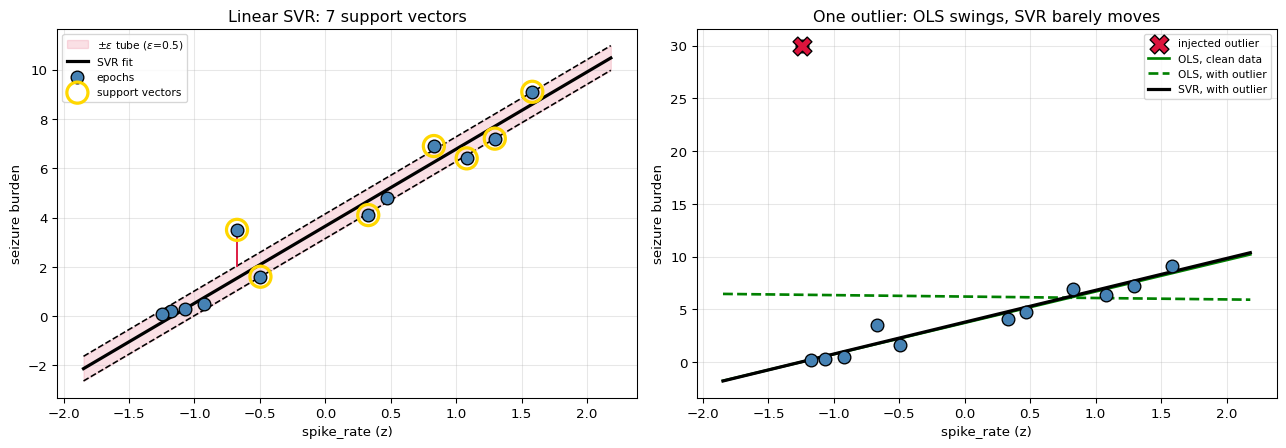

slope with clean data      : OLS +2.9724   SVR +3.1276
slope after one outlier    : OLS -0.1357   SVR +3.0177
change                     : OLS +3.1081   SVR +0.1099

OLS moved 28.3x more than SVR. The squared loss grows without bound; the
eps-insensitive loss grows only linearly, so one bad point cannot dominate.


In [6]:
xs = np.linspace(x1.min()-.6, x1.max()+.6, 300)[:, None]
line = svr1.predict(xs)

fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.8))

ax = axes[0]
ax.fill_between(xs.ravel(), line-EPS, line+EPS, color="crimson", alpha=.13,
                label=f"$\\pm\\varepsilon$ tube ($\\varepsilon$={EPS})")
ax.plot(xs, line, "k-", lw=2.4, label="SVR fit")
ax.plot(xs, line+EPS, "k--", lw=1.2)
ax.plot(xs, line-EPS, "k--", lw=1.2)
ax.scatter(x1, y, s=90, c="steelblue", edgecolor="k", zorder=3, label="epochs")
ax.scatter(x1[svr1.support_], y[svr1.support_], s=250, facecolors="none",
           edgecolors="gold", linewidths=2.4, zorder=4, label="support vectors")
for i in range(n_samples):
    if abs(resid1[i]) > EPS:
        ax.plot([x1[i,0], x1[i,0]],
                [y[i], pred1[i] + np.sign(resid1[i])*EPS],
                color="crimson", lw=1.4, zorder=2)
ax.set(xlabel=feature_names[1]+" (z)", ylabel="seizure burden",
       title=f"Linear SVR: {len(svr1.support_)} support vectors")
ax.legend(fontsize=8); ax.grid(alpha=.3)

ax = axes[1]
from sklearn.linear_model import LinearRegression
ols = LinearRegression().fit(x1, y)
y_out = y.copy(); y_out[4] = 30.0                # inject one wild outlier
ols_o = LinearRegression().fit(x1, y_out)
svr_o = SVR(kernel="linear", C=CVAL, epsilon=EPS).fit(x1, y_out)
ax.scatter(x1, y_out, s=90, c="steelblue", edgecolor="k", zorder=3)
ax.scatter([x1[4,0]], [y_out[4]], s=200, c="crimson", marker="X",
           edgecolor="k", zorder=4, label="injected outlier")
ax.plot(xs, ols.predict(xs), "g-", lw=2, label="OLS, clean data")
ax.plot(xs, ols_o.predict(xs), "g--", lw=2, label="OLS, with outlier")
ax.plot(xs, svr_o.predict(xs), "k-", lw=2.4, label="SVR, with outlier")
ax.set(xlabel=feature_names[1]+" (z)", ylabel="seizure burden",
       title="One outlier: OLS swings, SVR barely moves")
ax.legend(fontsize=8); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

print(f"slope with clean data      : OLS {ols.coef_[0]:+.4f}   "
      f"SVR {svr1.coef_[0][0]:+.4f}")
print(f"slope after one outlier    : OLS {ols_o.coef_[0]:+.4f}   "
      f"SVR {svr_o.coef_[0][0]:+.4f}")
print(f"change                     : OLS {abs(ols_o.coef_[0]-ols.coef_[0]):+.4f}   "
      f"SVR {abs(svr_o.coef_[0][0]-svr1.coef_[0][0]):+.4f}")
print(f"\nOLS moved {abs(ols_o.coef_[0]-ols.coef_[0])/max(abs(svr_o.coef_[0][0]-svr1.coef_[0][0]),1e-9):.1f}x "
      f"more than SVR. The squared loss grows without bound; the")
print(f"eps-insensitive loss grows only linearly, so one bad point cannot dominate.")

---
# 4. What $\varepsilon$ and $C$ Do

They pull in different directions:

* **$\varepsilon$** sets the tube width. Wider tube &rarr; more points inside &rarr; **fewer**
  support vectors &rarr; a simpler, flatter model. At $\varepsilon$ larger than the spread
  of $y$, every point fits inside and the model collapses to a constant.
* **$C$** sets the price of leaving the tube. Large $C$ &rarr; violations are expensive &rarr;
  the fit bends to accommodate them.

In [7]:
print(f"{'epsilon':>9}  {'#SV':>5}  {'||w||':>9}  {'train MSE':>11}  "
      f"{'mean |resid|':>13}")
print("-" * 56)
for e in (0.0, 0.25, 0.5, 1.0, 2.0, 4.0, 8.0):
    m = SVR(kernel="linear", C=CVAL, epsilon=e).fit(Xz, y)
    r = y - m.predict(Xz)
    print(f"{e:>9.2f}  {len(m.support_):>5}  {np.linalg.norm(m.coef_[0]):>9.4f}  "
          f"{(r**2).mean():>11.4f}  {np.abs(r).mean():>13.4f}")
print("-" * 56)
print(f"\n(the spread of y is {y.max()-y.min():.1f}, so epsilon = 8 swallows nearly")
print(f" everything and the model gives up)\n")

print(f"{'C':>9}  {'#SV':>5}  {'||w||':>9}  {'train MSE':>11}")
print("-" * 40)
for cv in (0.01, 0.1, 1.0, 10.0, 100.0, 1000.0):
    m = SVR(kernel="linear", C=cv, epsilon=EPS).fit(Xz, y)
    r = y - m.predict(Xz)
    print(f"{cv:>9.2f}  {len(m.support_):>5}  {np.linalg.norm(m.coef_[0]):>9.4f}  "
          f"{(r**2).mean():>11.4f}")
print("-" * 40)
print("\nSmall C keeps ||w|| tiny and underfits badly; large C chases the data.")

  epsilon    #SV      ||w||    train MSE   mean |resid|
--------------------------------------------------------
     0.00     12     2.1562       0.6527         0.3962
     0.25      7     2.1527       0.4244         0.4314
     0.50      5     2.2364       0.4535         0.4873
     1.00      5     2.6147       0.7047         0.7761
     2.00      2     1.3172       1.4003         1.0150
     4.00      2     0.1987       8.2204         2.4906
     8.00      0     0.0000      10.0792         2.7750
--------------------------------------------------------

(the spread of y is 9.0, so epsilon = 8 swallows nearly
 everything and the model gives up)

        C    #SV      ||w||    train MSE
----------------------------------------
     0.01     10     0.1644       7.7968
     0.10     10     1.3176       1.2068
     1.00      5     1.8339       0.5774
    10.00      5     2.2364       0.4535
   100.00      6     2.8242       0.4168
  1000.00      6     2.8240       0.4167
----------------

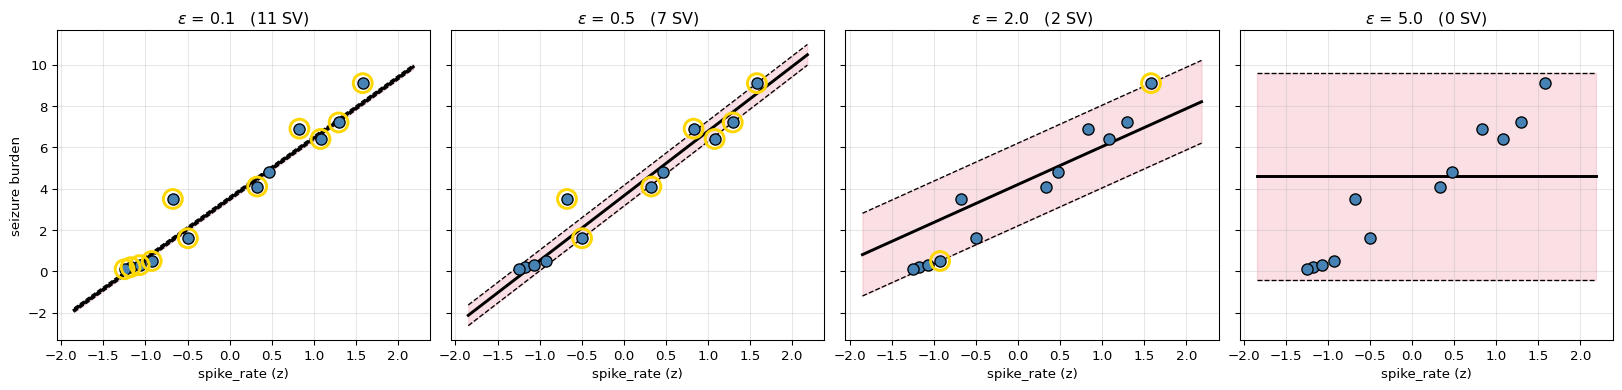

As the tube widens the gold circles disappear one by one - the model is
built from fewer and fewer points, and eventually stops tracking the data.


In [8]:
fig, axes = plt.subplots(1, 4, figsize=(17, 4.2), sharey=True)
for ax, e in zip(axes, (0.1, 0.5, 2.0, 5.0)):
    m = SVR(kernel="linear", C=CVAL, epsilon=e).fit(x1, y)
    ln = m.predict(xs)
    ax.fill_between(xs.ravel(), ln-e, ln+e, color="crimson", alpha=.13)
    ax.plot(xs, ln, "k-", lw=2.2)
    ax.plot(xs, ln+e, "k--", lw=1); ax.plot(xs, ln-e, "k--", lw=1)
    ax.scatter(x1, y, s=70, c="steelblue", edgecolor="k", zorder=3)
    ax.scatter(x1[m.support_], y[m.support_], s=200, facecolors="none",
               edgecolors="gold", linewidths=2.2, zorder=4)
    ax.set(title=f"$\\varepsilon$ = {e}   ({len(m.support_)} SV)",
           xlabel=feature_names[1]+" (z)")
    ax.grid(alpha=.3)
axes[0].set_ylabel("seizure burden")
plt.tight_layout(); plt.show()

print("As the tube widens the gold circles disappear one by one - the model is")
print("built from fewer and fewer points, and eventually stops tracking the data.")

---
# 5. Kernels, and Prediction Through Them

The dual has the same shape as the classifier's, and again the data enters only through
inner products. So the same kernels apply, and prediction is:

$$f(\mathbf{x}) = \sum_{i \in SV}(\alpha_i - \alpha_i^{*})\,K(\mathbf{x}_i, \mathbf{x}) + b$$

`sklearn` stores the combined coefficient $(\alpha_i - \alpha_i^{*})$ in `dual_coef_`.
Below that sum is evaluated by hand and checked against `predict`.

In [9]:
rbf = SVR(kernel="rbf", C=CVAL, epsilon=EPS, gamma=0.5).fit(Xz, y)
dc = rbf.dual_coef_[0]
svs = rbf.support_vectors_
b_r = float(rbf.intercept_[0])

i_test = 5
xq = Xz[i_test]
kv = np.exp(-0.5 * np.sum((svs - xq)**2, axis=1))

print(f"predicting {rec_ids[i_test]} (true y = {y[i_test]:.2f})\n")
print(f"{'SV':>7}  {'alpha-alpha*':>13}  {'K(sv,x)':>10}  {'product':>11}")
print("-" * 46)
for k, i in enumerate(rbf.support_):
    print(f"{rec_ids[i]:>7}  {dc[k]:>13.5f}  {kv[k]:>10.6f}  {dc[k]*kv[k]:>11.6f}")
print("-" * 46)
tot = float(dc @ kv)
print(f"{'sum':>7}  {'':>13}  {'':>10}  {tot:>11.6f}")
print(f"\nf(x) = {tot:.6f} + b({b_r:+.6f}) = {tot + b_r:.6f}")
print(f"sklearn predict            = {rbf.predict(xq[None,:])[0]:.6f}")
print(f"MATCH: {np.isclose(tot + b_r, rbf.predict(xq[None,:])[0])}")

mine = np.array([float(np.exp(-0.5*np.sum((svs-Xz[i])**2,axis=1)) @ dc) + b_r
                 for i in range(n_samples)])
print(f"\nall {n_samples} predictions by hand MATCH sklearn: "
      f"{np.allclose(mine, rbf.predict(Xz))}")

print(f"\n\ncoefficients are bounded by C = {CVAL}:")
print(f"   max |alpha - alpha*| = {np.abs(dc).max():.6f}")
print(f"   all within [-C, C]? {np.all(np.abs(dc) <= CVAL + 1e-9)}")
print(f"   at the bound (fully outside the tube): "
      f"{int(np.sum(np.isclose(np.abs(dc), CVAL, atol=1e-6)))} of {len(dc)}")

predicting rec05 (true y = 9.10)

     SV   alpha-alpha*     K(sv,x)      product
----------------------------------------------
  rec01       -2.10722    0.000135    -0.000285
  rec03        1.46736    0.160542     0.235572
  rec04       -2.22656    0.000003    -0.000007
  rec05        4.59669    1.000000     4.596690
  rec06        4.95842    0.007455     0.036964
  rec10       -6.68870    0.029305    -0.196011
----------------------------------------------
    sum                                4.672923

f(x) = 4.672923 + b(+3.927051) = 8.599974
sklearn predict            = 8.599974
MATCH: True

all 12 predictions by hand MATCH sklearn: True


coefficients are bounded by C = 10.0:
   max |alpha - alpha*| = 6.688696
   all within [-C, C]? True
   at the bound (fully outside the tube): 0 of 6


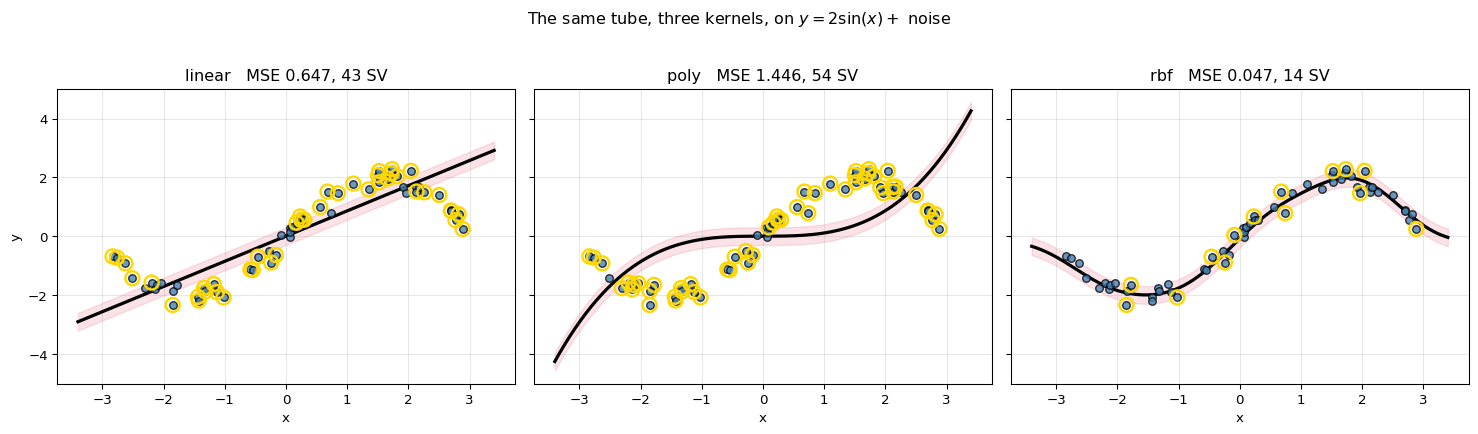

    kernel        MSE    #SV   SV fraction
------------------------------------------
    linear     0.6474     43        71.7%
      poly     1.4457     54        90.0%
       rbf     0.0470     14        23.3%
------------------------------------------

The RBF fit tracks the sine closely while still ignoring every point that
lands inside the tube - accuracy and sparsity at the same time.


In [10]:
rng = np.random.default_rng(1)
xn = np.sort(rng.uniform(-3, 3, 60))[:, None]
yn = np.sin(xn.ravel()) * 2 + rng.normal(0, .25, 60)
xg = np.linspace(-3.4, 3.4, 400)[:, None]

fig, axes = plt.subplots(1, 3, figsize=(15.5, 4.4), sharey=True)
for ax, (kn, kw) in zip(axes, [("linear", {}), ("poly", dict(degree=3, gamma=1.0)),
                               ("rbf", dict(gamma=1.0))]):
    m = SVR(kernel=kn, C=10.0, epsilon=0.3, **kw).fit(xn, yn)
    ln = m.predict(xg)
    ax.fill_between(xg.ravel(), ln-0.3, ln+0.3, color="crimson", alpha=.12)
    ax.plot(xg, ln, "k-", lw=2.4)
    ax.scatter(xn, yn, s=32, c="steelblue", edgecolor="k", alpha=.8, zorder=3)
    ax.scatter(xn[m.support_], yn[m.support_], s=110, facecolors="none",
               edgecolors="gold", linewidths=1.8, zorder=4)
    r = yn - m.predict(xn)
    ax.set(title=f"{kn}   MSE {(r**2).mean():.3f}, {len(m.support_)} SV", xlabel="x")
    ax.grid(alpha=.3)
axes[0].set_ylabel("y")
plt.suptitle("The same tube, three kernels, on $y = 2\\sin(x) + $ noise", y=1.02)
plt.tight_layout(); plt.show()

print(f"{'kernel':>10}  {'MSE':>9}  {'#SV':>5}  {'SV fraction':>12}")
print("-" * 42)
for kn, kw in [("linear", {}), ("poly", dict(degree=3, gamma=1.0)), ("rbf", dict(gamma=1.0))]:
    m = SVR(kernel=kn, C=10.0, epsilon=0.3, **kw).fit(xn, yn)
    r = yn - m.predict(xn)
    print(f"{kn:>10}  {(r**2).mean():>9.4f}  {len(m.support_):>5}  "
          f"{len(m.support_)/len(xn):>11.1%}")
print("-" * 42)
print("\nThe RBF fit tracks the sine closely while still ignoring every point that")
print("lands inside the tube - accuracy and sparsity at the same time.")

---
# 6. Checking Against scikit-learn

In [11]:
lin_full = SVR(kernel="linear", C=CVAL, epsilon=EPS).fit(Xz, y)
w_from_dual = (lin_full.dual_coef_[0][:, None] * lin_full.support_vectors_).sum(axis=0)

print("linear SVR: recover w from the dual coefficients")
print("-" * 58)
print(f"w = sum_i (alpha_i - alpha_i*) x_i")
print(f"   from dual   : {np.round(w_from_dual, 8)}")
print(f"   sklearn coef: {np.round(lin_full.coef_[0], 8)}")
print(f"   MATCH: {np.allclose(w_from_dual, lin_full.coef_[0])}")

f_hand = Xz @ w_from_dual + float(lin_full.intercept_[0])
print(f"\npredictions by hand MATCH sklearn: "
      f"{np.allclose(f_hand, lin_full.predict(Xz))}")

print(f"\n\nthe eps-insensitive loss, evaluated directly")
print("-" * 58)
r = y - lin_full.predict(Xz)
loss = np.maximum(0, np.abs(r) - EPS)
obj = 0.5*np.dot(w_from_dual, w_from_dual) + CVAL*loss.sum()
print(f"   0.5*||w||^2       = {0.5*np.dot(w_from_dual,w_from_dual):.6f}")
print(f"   C * sum of losses = {CVAL} * {loss.sum():.6f} = {CVAL*loss.sum():.6f}")
print(f"   objective         = {obj:.6f}")

rng_p = np.random.default_rng(0)
better = 0
for _ in range(4000):
    pw = w_from_dual + rng_p.normal(scale=.03, size=n_features)
    pb = float(lin_full.intercept_[0]) + rng_p.normal(scale=.03)
    rr = y - (Xz @ pw + pb)
    o = 0.5*np.dot(pw, pw) + CVAL*np.maximum(0, np.abs(rr)-EPS).sum()
    if o < obj - 1e-9:
        better += 1
print(f"   random perturbations that beat it: {better}/4000")

print(f"\n\nthe support-vector rule, and where solver tolerance shows up")
print("-" * 58)
TOL = 1e-3                      # libsvm's default stopping tolerance
sv_set = set(lin_full.support_.tolist())
dual_by_i = dict(zip(lin_full.support_.tolist(), lin_full.dual_coef_[0]))

print(f"{'id':>7}  {'|resid| - eps':>15}  {'region':>16}  {'SV?':>5}  {'alpha-alpha*':>13}")
print("-" * 64)
clear_in, clear_out, boundary = [], [], []
for i in np.argsort(np.abs(r) - EPS):
    gap = abs(r[i]) - EPS
    if gap < -TOL:
        region, bucket = "inside", clear_in
    elif gap > TOL:
        region, bucket = "outside", clear_out
    else:
        region, bucket = "ON the boundary", boundary
    bucket.append(i)
    a = dual_by_i.get(i)
    print(f"{rec_ids[i]:>7}  {gap:>15.2e}  {region:>16}  "
          f"{'yes' if i in sv_set else 'no':>5}  "
          f"{(f'{a:+.5f}' if a is not None else '0'):>13}")
print("-" * 64)

print(f"\n   clearly inside  ({len(clear_in)}): any of them support vectors? "
      f"{bool(set(clear_in) & sv_set)}")
print(f"   clearly outside ({len(clear_out)}): all of them support vectors? "
      f"{set(clear_out) <= sv_set}")
print(f"   on the boundary ({len(boundary)}): decided by the solver, not by us")

print(f"\n   In exact arithmetic a point is a support vector precisely when it is")
print(f"   not strictly inside the tube. libsvm stops at tol = {TOL}, so points")
print(f"   sitting within that distance of the wall can be kept with a small")
print(f"   non-zero alpha - see the boundary rows above, whose |alpha| are the")
print(f"   smallest in the model while the far-outside points sit at C = {CVAL}.")

linear SVR: recover w from the dual coefficients
----------------------------------------------------------
w = sum_i (alpha_i - alpha_i*) x_i
   from dual   : [0.7688 2.0932 0.1698]
   sklearn coef: [0.7688 2.0932 0.1698]
   MATCH: True

predictions by hand MATCH sklearn: True


the eps-insensitive loss, evaluated directly
----------------------------------------------------------
   0.5*||w||^2       = 2.500772
   C * sum of losses = 10.0 * 1.593203 = 15.932028
   objective         = 18.432799
   random perturbations that beat it: 0/4000


the support-vector rule, and where solver tolerance shows up
----------------------------------------------------------
     id    |resid| - eps            region    SV?   alpha-alpha*
----------------------------------------------------------------
  rec00        -4.55e-01            inside     no              0
  rec09        -3.93e-01            inside     no              0
  rec04        -3.87e-01            inside     no              0
  rec07

---
# 7. Summary

| Concept | Formula |
|---|---|
| Loss | $\max(0, \lvert y-\hat y\rvert - \varepsilon)$ |
| Objective | $\tfrac12\lVert\mathbf{w}\rVert^2 + C\sum_i(\xi_i+\xi_i^{*})$ |
| Predict | $\sum_{i\in SV}(\alpha_i-\alpha_i^{*})K(\mathbf{x}_i,\mathbf{x}) + b$ |
| Support vector | any point **not strictly inside** the tube |
| $\varepsilon$ larger | wider tube, fewer SVs, simpler model |
| $C$ larger | violations costlier, fit bends more |

**The one idea:** make the loss **flat** near zero. That single change turns a regression
into a sparse, margin-based problem &mdash; the points that fit well drop out of the model
entirely, and the ones that remain define it.

**Why it resists outliers:** beyond $\varepsilon$ the penalty grows *linearly*, not
quadratically. A point ten units away is ten times as costly, not a hundred times, so it
cannot dominate the fit the way it does in least squares.

**What is deliberately left out:** the full dual derivation with both $\alpha$ and
$\alpha^{*}$, the KKT conditions, $\nu$-SVR (which sets the fraction of support vectors
instead of $\varepsilon$), and the $O(n^2)$&ndash;$O(n^3)$ scaling that makes SVR impractical
on large datasets.